# Các chỉ số đánh giá: Accuracy, Precision, Recall, F1-Score, ROC-AUC

*Bài 4, mục 4.1.6.* Tiếp tục với mô hình thi đỗ ở notebook 04.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, roc_curve, roc_auc_score)

X = np.array([0.50, 0.75, 1.00, 1.25, 1.50, 1.75, 1.75, 2.00, 2.25, 2.50,
              2.75, 3.00, 3.25, 3.50, 4.00, 4.25, 4.50, 4.75, 5.00, 5.50])
y = np.array([0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1])
w0, w1 = -4.0777, 1.5046

p = 1 / (1 + np.exp(-(w0 + w1 * X)))          # xác suất dự đoán lớp 1
y_pred = (p >= 0.5).astype(int)

## 1. Tính tay từ TP, TN, FP, FN

$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}, \quad \text{Precision} = \frac{TP}{TP + FP}, \quad \text{Recall} = \frac{TP}{TP + FN}, \quad F_1 = \frac{2\,TP}{2\,TP + FP + FN}$$

In [2]:
tp = np.sum((y == 1) & (y_pred == 1))
tn = np.sum((y == 0) & (y_pred == 0))
fp = np.sum((y == 0) & (y_pred == 1))
fn = np.sum((y == 1) & (y_pred == 0))
print('Accuracy  = %.3f' % ((tp + tn) / (tp + tn + fp + fn)))
print('Precision = %.3f' % (tp / (tp + fp)))
print('Recall    = %.3f' % (tp / (tp + fn)))
print('F1        = %.3f' % (2 * tp / (2 * tp + fp + fn)))

Accuracy  = 0.800
Precision = 0.800
Recall    = 0.800
F1        = 0.800


## 2. Dùng scikit-learn

In [3]:
print('Accuracy :', accuracy_score(y, y_pred))
print('Precision:', precision_score(y, y_pred))
print('Recall   :', recall_score(y, y_pred))
print('F1       :', f1_score(y, y_pred))
print(classification_report(y, y_pred))

Accuracy : 0.8
Precision: 0.8
Recall   : 0.8
F1       : 0.8
              precision    recall  f1-score   support

           0       0.80      0.80      0.80        10
           1       0.80      0.80      0.80        10

    accuracy                           0.80        20
   macro avg       0.80      0.80      0.80        20
weighted avg       0.80      0.80      0.80        20



## 3. Đường cong ROC và AUC

Với mỗi ngưỡng, tính $\text{TPR} = \frac{TP}{TP + FN}$ và $\text{FPR} = \frac{FP}{FP + TN}$. AUC phải tính trên **xác suất** dự đoán, không phải nhãn 0/1.

ngưỡng inf -> FPR = 0.00, TPR = 0.00
ngưỡng 0.985 -> FPR = 0.00, TPR = 0.10
ngưỡng 0.874 -> FPR = 0.00, TPR = 0.60
ngưỡng 0.766 -> FPR = 0.10, TPR = 0.60
ngưỡng 0.693 -> FPR = 0.10, TPR = 0.70
ngưỡng 0.607 -> FPR = 0.20, TPR = 0.70
ngưỡng 0.515 -> FPR = 0.20, TPR = 0.80
ngưỡng 0.422 -> FPR = 0.30, TPR = 0.80
ngưỡng 0.334 -> FPR = 0.30, TPR = 0.90
ngưỡng 0.256 -> FPR = 0.40, TPR = 0.90
ngưỡng 0.191 -> FPR = 0.50, TPR = 1.00
ngưỡng 0.035 -> FPR = 1.00, TPR = 1.00
AUC = 0.895


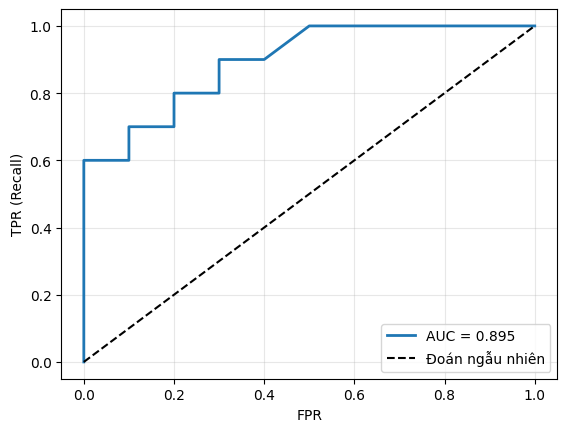

In [4]:
fpr, tpr, thresholds = roc_curve(y, p)
for a, b, t in zip(fpr, tpr, thresholds):
    print('ngưỡng %.3f -> FPR = %.2f, TPR = %.2f' % (t, a, b))
print('AUC =', roc_auc_score(y, p))

plt.plot(fpr, tpr, lw=2, label='AUC = %.3f' % roc_auc_score(y, p))
plt.plot([0, 1], [0, 1], 'k--', label='Đoán ngẫu nhiên')
plt.xlabel('FPR'); plt.ylabel('TPR (Recall)')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

## 4. Hạn chế của Accuracy với dữ liệu mất cân bằng

1000 người, chỉ 10 người bệnh. Mô hình luôn trả lời "không bệnh" có Accuracy rất cao nhưng bỏ sót toàn bộ người bệnh.

In [5]:
y_sick = np.r_[np.ones(10), np.zeros(990)]
y_always_0 = np.zeros(1000)
print('Accuracy = %.2f, Recall = %.2f' % (accuracy_score(y_sick, y_always_0),
                                         recall_score(y_sick, y_always_0)))

Accuracy = 0.99, Recall = 0.00
